# Nivel 3 — Anatomía de una tormenta en alta montaña

En esta primera etapa inspeccionamos las tablas antes de construir variables o modelos. Cargamos los CSV directamente desde la raíz del kit, revisamos filas iniciales, tipos, rangos de fecha, distribuciones y faltantes.

**Pregunta física:** ¿qué combinación de lluvia, temperatura/isoterma y transporte de vapor coincide con las crecidas invernales del Maipo?

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents)
             if (path / "nivel1/nivel1_manzano.csv").exists()), Path.cwd())

n1 = pd.read_csv(ROOT / "nivel1/nivel1_manzano.csv", parse_dates=["fecha"])
n2 = pd.read_csv(ROOT / "nivel2/nivel2_tributarios.csv", parse_dates=["fecha"])
n3 = pd.read_csv(ROOT / "nivel3/nivel3_tormentas.csv", parse_dates=["fecha"])
zonas = pd.read_csv(ROOT / "nivel3/zonas.csv")

for nombre, tabla in [("Nivel 1 — El Manzano", n1),
                      ("Nivel 2 — Tributarios", n2),
                      ("Nivel 3 — Tormentas", n3)]:
    display(Markdown(f"### {nombre}: {tabla.shape[0]:,} filas × {tabla.shape[1]} columnas"))
    display(tabla.head(3))
    tabla.info()
    print(f"Rango: {tabla['fecha'].min().date()} a {tabla['fecha'].max().date()} | "
          f"fechas únicas: {tabla['fecha'].nunique():,} | "
          f"fechas duplicadas: {tabla['fecha'].duplicated().sum()}")
    display(tabla.describe().T.round(2))
    faltantes = tabla.isna().sum().sort_values(ascending=False)
    display(faltantes[faltantes.gt(0)].to_frame("faltantes"))

display(Markdown(f"### Zonas: {zonas.shape[0]} filas × {zonas.shape[1]} columnas"))
display(zonas.head(8))
zonas.info()
display(zonas.describe(include="all").T)


### Nivel 1 — El Manzano: 9,709 filas × 20 columnas

,fecha,anio_hidro,mes,q_m3s,ssc_mgL,ssc_hora_h,p_mm,p_acum3d_mm,t_media_C,iso0_m,iso0_fuente,frac_bajo_iso0,p_liq_mm,p_liq_48h_mm,evento_documentado,evento_causa,evento_fuente,duracion_evento_h,iso0_reportada_m,ssc_pico_estimado_mgL
0,2000-01-01,1999,1,161.0,NaN,NaN,0.01,0.01,9.44,4325.0,igra,0.9082,0.01,0.01,0,NaN,NaN,NaN,NaN,NaN
1,2000-01-02,1999,1,163.0,NaN,NaN,0.00,0.01,9.82,4168.0,igra,0.8773,0.00,0.01,0,NaN,NaN,NaN,NaN,NaN
2,2000-01-03,1999,1,160.0,NaN,NaN,0.42,0.43,7.95,4007.0,igra,0.8366,0.35,0.35,0,NaN,NaN,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9709 entries, 0 to 9708
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   fecha                  9709 non-null   datetime64[ns]
 1   anio_hidro             9709 non-null   int64         
 2   mes                    9709 non-null   int64         
 3   q_m3s                  9653 non-null   float64       
 4   ssc_mgL                5258 non-null   float64       
 5   ssc_hora_h             5140 non-null   float64       
 6   p_mm                   9709 non-null   float64       
 7   p_acum3d_mm            9709 non-null   float64       
 8   t_media_C              9678 non-null   float64       
 9   iso0_m                 9709 non-null   float64       
 10  iso0_fuente            9709 non-null   object        
 11  frac_bajo_iso0         9709 non-null   float64       
 12  p_liq_mm               9709 non-null   float64       
 13  p_l

,count,mean,min,25%,50%,75%,max,std
fecha,9709,2013-04-16 00:00:00,2000-01-01 00:00:00,2006-08-24 00:00:00,2013-04-16 00:00:00,2019-12-08 00:00:00,2026-07-31 00:00:00,NaN
anio_hidro,9709.0,2012.543413,1999.0,2006.0,2013.0,2019.0,2026.0,7.68197
mes,9709.0,6.468019,1.0,3.0,6.0,9.0,12.0,3.443423
q_m3s,9653.0,93.000671,10.6,51.8,70.9,110.0,768.0,69.867067
ssc_mgL,5258.0,420.507919,1.63,65.7,181.695,523.0275,9769.96,629.041595
ssc_hora_h,5140.0,8.023346,8.0,8.0,8.0,8.0,18.0,0.482663
p_mm,9709.0,2.669999,0.0,0.0,0.0,0.74,117.22,8.530026
p_acum3d_mm,9709.0,8.0046,0.0,0.0,0.39,6.28,271.68,19.961809
t_media_C,9678.0,3.941046,-11.85,-0.27,4.57,8.55,15.54,5.431217
iso0_m,9709.0,3645.685549,867.0,3154.0,3766.0,4213.0,5480.0,786.113165


,faltantes
ssc_pico_estimado_mgL,9684
iso0_reportada_m,9681
duracion_evento_h,9680
evento_causa,9622
evento_fuente,9622
ssc_hora_h,4569
ssc_mgL,4451
q_m3s,56
t_media_C,31


...

,faltantes
q_hualtatas_m3s,3483
ivt_mms,1475
pw_mm,1428
ki_C,775
t_700_C,343
t_melosas_resto_C,31
t_hualtatas_C,31
t_olivares_C,31
t_colorado_alto_C,31
t_manzano_local_C,31


### Zonas: 8 filas × 9 columnas

,zona,nombre,rama,caudal_propio,area_km2,elev_media_m,pend_media_deg,pct_glaciar,pct_area_sobre_4000m
0,hualtatas,Río Maipo en Las Hualtatas,san_alfonso,q_hualtatas_m3s,1035.5,3320.0,28.5,7.6,10.7
1,melosas_resto,Río Maipo entre Las Hualtatas y Las Melosas,san_alfonso,NaN,427.2,2881.0,28.9,0.1,0.8
2,volcan,Río Volcán en Queltehues,san_alfonso,q_volcan_m3s,523.4,3368.0,28.3,14.2,18.6
3,yeso,Subcuenca Río Yeso + intermedio hasta San Alfonso,san_alfonso,NaN,800.6,3084.0,26.9,5.3,12.6
4,colorado_alto,Río Colorado antes junta Río Olivares,colorado,q_colorado_alto_m3s,783.3,3733.0,29.6,9.5,34.8
5,olivares,Río Olivares antes junta Río Colorado,colorado,q_olivares_m3s,541.5,3688.0,28.8,14.3,39.4
6,colorado_bajo,Río Colorado bajo (sector Maitenes),colorado,NaN,337.9,2248.0,26.2,0.0,0.1
7,manzano_local,Aporte lateral entre San Alfonso/Colorado y El...,local,NaN,389.5,2092.0,25.0,0.0,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   zona                  8 non-null      object 
 1   nombre                8 non-null      object 
 2   rama                  8 non-null      object 
 3   caudal_propio         4 non-null      object 
 4   area_km2              8 non-null      float64
 5   elev_media_m          8 non-null      float64
 6   pend_media_deg        8 non-null      float64
 7   pct_glaciar           8 non-null      float64
 8   pct_area_sobre_4000m  8 non-null      float64
dtypes: float64(5), object(4)
memory usage: 708.0+ bytes


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
zona,8,8,hualtatas,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nombre,8,8,Río Maipo en Las Hualtatas,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rama,8,3,san_alfonso,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
caudal_propio,4,4,q_hualtatas_m3s,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_km2,8.0,NaN,NaN,NaN,604.8625,243.623439,337.9,417.775,532.45,787.625,1035.5
elev_media_m,8.0,NaN,NaN,NaN,3051.75,613.91222,2092.0,2722.75,3202.0,3448.0,3733.0
pend_media_deg,8.0,NaN,NaN,NaN,27.775,1.576388,25.0,26.725,28.4,28.825,29.6
pct_glaciar,8.0,NaN,NaN,NaN,6.375,6.060587,0.0,0.075,6.45,10.675,14.3
pct_area_sobre_4000m,8.0,NaN,NaN,NaN,14.625,15.455628,0.0,0.625,11.65,22.65,39.4


## 1. Catálogo de tormentas invernales

Seguimos la guía del Nivel 3: una tormenta es una racha de días consecutivos entre abril y septiembre con `p_mm >= 10`. La respuesta se mide como el caudal máximo desde el primer día hasta dos días después del último, dividido por la mediana de los siete días previos; `crecida` vale 1 si la razón es al menos 3. Para etiquetar, exigimos caudal observado en los siete dias de referencia y en todos los dias de respuesta; las ventanas incompletas quedan sin etiqueta, no como ausencia de crecida.

Clasificamos usando el máximo observado durante los días de lluvia: cálida si `iso0_m >= 3000 m`, río atmosférico si `pw_mm >= 20` **y** `ivt_mms >= 250`, y convectiva si `ki_C >= 30`. Cuando falta el sondeo, la clasificación correspondiente queda sin dato. Sumamos lluvia líquida solo sobre los días de tormenta y las ocho zonas no solapadas. `evento_documentado` se usa para contrastar el catálogo y puede caer en la ventana de respuesta; no será predictor del modelo.

In [2]:
df = n1.merge(n2, on="fecha", validate="one_to_one").merge(
    n3, on="fecha", validate="one_to_one"
)
assert len(df) == len(n1) == len(n2) == len(n3)

en_invierno = df["fecha"].dt.month.between(4, 9)
dias_tormenta = df.loc[en_invierno & df["p_mm"].ge(10)].copy()
dias_tormenta["tormenta_id"] = (
    dias_tormenta["fecha"].diff().dt.days.ne(1).cumsum()
)

dias_evento = df.loc[
    en_invierno & df["evento_documentado"].eq(1), ["fecha"]
].copy()
dias_evento["evento_id"] = dias_evento["fecha"].diff().dt.days.ne(1).cumsum()
eventos_documentados = (
    dias_evento.groupby("evento_id", as_index=False)
    .agg(fecha_evento_inicio=("fecha", "min"), fecha_evento_fin=("fecha", "max"))
)

columnas_lluvia_zonal = [f"p_liq_{zona}_mm" for zona in zonas["zona"]]
assert set(columnas_lluvia_zonal).issubset(df.columns)

filas_catalogo = []
for tormenta_id, dias in dias_tormenta.groupby("tormenta_id", sort=True):
    inicio = dias["fecha"].iloc[0]
    fin = dias["fecha"].iloc[-1]
    fin_respuesta = fin + pd.Timedelta(days=2)

    referencia = df.loc[
        df["fecha"].ge(inicio - pd.Timedelta(days=7)) & df["fecha"].lt(inicio),
        "q_m3s",
    ].dropna()
    respuesta = df.loc[df["fecha"].between(inicio, fin_respuesta), "q_m3s"].dropna()
    dias_respuesta_esperados = (fin_respuesta - inicio).days + 1
    q_mediana_previa = referencia.median() if len(referencia) == 7 else float("nan")
    q_max_respuesta = (
        respuesta.max() if len(respuesta) == dias_respuesta_esperados else float("nan")
    )
    razon_respuesta = (
        q_max_respuesta / q_mediana_previa
        if pd.notna(q_max_respuesta) and pd.notna(q_mediana_previa) and q_mediana_previa > 0
        else float("nan")
    )

    eventos_en_ventana = eventos_documentados.loc[
        eventos_documentados["fecha_evento_inicio"].le(fin_respuesta)
        & eventos_documentados["fecha_evento_fin"].ge(inicio),
        "evento_id",
    ]
    iso0_max = dias["iso0_m"].max()
    pw_max = dias["pw_mm"].max()
    ivt_max = dias["ivt_mms"].max()
    ki_max = dias["ki_C"].max()

    fila = {
        "tormenta_id": int(tormenta_id),
        "fecha_inicio": inicio,
        "fecha_fin": fin,
        "dias_con_p_ge_10": len(dias),
        "p_total_mm": dias["p_mm"].sum(),
        "iso0_max_m": iso0_max,
        "pw_max_mm": pw_max,
        "ivt_max_mms": ivt_max,
        "ki_max_C": ki_max,
        "tormenta_calida": bool(iso0_max >= 3000),
        "rio_atmosferico": (
            pd.NA if pd.isna(pw_max) or pd.isna(ivt_max)
            else bool(pw_max >= 20 and ivt_max >= 250)
        ),
        "convectiva": pd.NA if pd.isna(ki_max) else bool(ki_max >= 30),
        "p_liq_total_zonas_mm": dias[columnas_lluvia_zonal].sum().sum(),
        "q_mediana_7d_previos_m3s": q_mediana_previa,
        "dias_respuesta_esperados": dias_respuesta_esperados,
        "n_q_validos_7d_previos": len(referencia),
        "q_max_respuesta_m3s": q_max_respuesta,
        "n_q_validos_respuesta": len(respuesta),
        "razon_respuesta": razon_respuesta,
        "crecida": pd.NA if pd.isna(razon_respuesta) else bool(razon_respuesta >= 3),
        "evento_documentado": not eventos_en_ventana.empty,
        "eventos_documentados_ids": ", ".join(map(str, eventos_en_ventana.astype(int))),
    }
    fila.update({col: dias[col].sum() for col in columnas_lluvia_zonal})
    filas_catalogo.append(fila)

catalogo = pd.DataFrame(filas_catalogo).sort_values("fecha_inicio").reset_index(drop=True)
ids_eventos_incluidos = {
    int(evento_id)
    for ids in catalogo["eventos_documentados_ids"]
    if ids
    for evento_id in ids.split(", ")
}
ids_asociados = [
    int(evento_id)
    for ids in catalogo["eventos_documentados_ids"]
    if ids
    for evento_id in ids.split(", ")
]
ids_eventos_faltantes = set(eventos_documentados["evento_id"]) - ids_eventos_incluidos
assert not ids_eventos_faltantes, f"Episodios documentados no asociados: {sorted(ids_eventos_faltantes)}"
assert len(ids_asociados) == len(set(ids_asociados)), "Un episodio documentado se asoció a más de una tormenta"
assert set(ids_asociados) == set(eventos_documentados["evento_id"]), "La asociación de episodios no coincide con los datos"

print(f"Tormentas de abril a septiembre: {len(catalogo)}")
print(f"Episodios documentados de abril a septiembre: {len(eventos_documentados)}")
print(f"Episodios documentados asociados a una ventana de respuesta: {len(ids_eventos_incluidos)}")
print(f"Episodios documentados sin tormenta asociada: {sorted(ids_eventos_faltantes)}")
print(f"Tormentas con respuesta de caudal calculable: {catalogo['razon_respuesta'].notna().sum()}")
print(f"Crecidas (razón >= 3): {catalogo['crecida'].eq(True).sum()} | "
      f"respuestas desconocidas: {catalogo['crecida'].isna().sum()}")

columnas_resumen = [
    "tormenta_id", "fecha_inicio", "fecha_fin", "p_total_mm", "iso0_max_m",
    "pw_max_mm", "ivt_max_mms", "ki_max_C", "tormenta_calida",
    "rio_atmosferico", "convectiva", "razon_respuesta", "crecida",
    "evento_documentado", "eventos_documentados_ids",
]
display(catalogo[columnas_resumen].head(10))
display(catalogo.loc[catalogo["evento_documentado"], columnas_resumen])


Tormentas de abril a septiembre: 346
Episodios documentados de abril a septiembre: 18
Episodios documentados asociados a una ventana de respuesta: 18
Episodios documentados sin tormenta asociada: []
Tormentas con respuesta de caudal calculable: 334
Crecidas (razón >= 3): 16 | respuestas desconocidas: 12


,tormenta_id,fecha_inicio,fecha_fin,p_total_mm,iso0_max_m,pw_max_mm,ivt_max_mms,ki_max_C,tormenta_calida,rio_atmosferico,convectiva,razon_respuesta,crecida,evento_documentado,eventos_documentados_ids
0,1,2000-04-13,2000-04-13,16.86,3982.0,20.35,0.00,11.0,True,False,False,1.193727,False,True,1
1,2,2000-05-02,2000-05-03,21.16,3025.0,13.06,61.38,19.0,True,False,False,1.016544,False,False,
2,3,2000-05-24,2000-05-24,19.94,4156.0,20.96,60.78,20.0,True,False,False,0.989940,False,False,
3,4,2000-06-12,2000-06-14,271.68,2848.0,26.32,483.30,28.0,False,True,False,5.756972,True,True,2
4,5,2000-06-20,2000-06-21,62.83,2760.0,22.16,358.00,27.0,False,True,False,1.302682,False,False,
5,6,2000-06-23,2000-06-24,52.10,2554.0,23.87,152.68,27.0,False,False,False,1.021429,False,False,
6,7,2000-06-26,2000-07-01,237.31,2808.0,28.17,391.56,30.0,False,True,True,4.742857,True,True,3
7,8,2000-07-06,2000-07-07,27.23,3522.0,21.54,339.79,23.0,True,True,False,0.824510,False,False,
8,9,2000-07-20,2000-07-20,40.55,3346.0,17.89,166.38,24.0,True,False,False,1.203390,False,False,
9,10,2000-08-21,2000-08-22,25.62,3242.0,16.26,145.85,16.0,True,False,False,1.255708,False,False,


,tormenta_id,fecha_inicio,fecha_fin,p_total_mm,iso0_max_m,pw_max_mm,ivt_max_mms,ki_max_C,tormenta_calida,rio_atmosferico,convectiva,razon_respuesta,crecida,evento_documentado,eventos_documentados_ids
0,1,2000-04-13,2000-04-13,16.86,3982.0,20.35,0.00,11.0,True,False,False,1.193727,False,True,1
3,4,2000-06-12,2000-06-14,271.68,2848.0,26.32,483.30,28.0,False,True,False,5.756972,True,True,2
6,7,2000-06-26,2000-07-01,237.31,2808.0,28.17,391.56,30.0,False,True,True,4.742857,True,True,3
13,14,2001-04-13,2001-04-13,12.34,3990.0,29.76,131.13,26.0,True,False,False,1.078947,False,True,4
24,25,2001-07-16,2001-07-19,188.81,3386.0,24.17,459.13,31.0,True,True,True,4.056291,True,True,5
25,26,2001-07-29,2001-07-30,134.36,2777.0,24.14,367.58,27.0,False,True,False,2.102497,False,True,6
30,31,2002-05-24,2002-05-27,166.52,3897.0,26.64,405.93,28.0,True,True,False,2.270992,False,True,7
36,37,2002-08-22,2002-08-24,130.03,3213.0,24.54,522.39,27.0,True,True,False,4.054404,True,True,8
43,44,2003-05-19,2003-05-21,122.79,3080.0,22.33,477.40,24.0,True,True,False,1.166432,False,True,9
81,82,2005-08-26,2005-08-28,190.24,3468.0,29.30,508.26,32.0,True,True,True,3.674322,True,True,10


## 2. Respuesta hidrológica y distribución espacial

Comparamos medianas y proporciones de crecidas entre los tipos de tormenta; son asociaciones observacionales, no pruebas de causalidad. Para las diez mayores razones de respuesta verificamos cuántas tienen evento documentado. Para comparar lluvia líquida con superficie, usamos `mm × km²` como proxy proporcional al volumen: las ocho zonas son particiones sin solape, así que no añadimos las ramas agregadas del Nivel 2.

### Isoterma >= 3.000 m

,tormentas,crecidas,razon_mediana,eventos_documentados,fraccion_crecidas
Clasificación,,,,,
No,130,4,1.041027,5,0.030769
Sí,204,12,1.077583,13,0.058824


Tormentas sin datos suficientes para esta clasificación: 0


### PW >= 20 mm e IVT >= 250 mm·m/s

,tormentas,crecidas,razon_mediana,eventos_documentados,fraccion_crecidas
Clasificación,,,,,
No,226,0,1.040913,2,0.000000
Sí,89,16,1.258621,16,0.179775


...

### KI >= 30 °C

,tormentas,crecidas,razon_mediana,eventos_documentados,fraccion_crecidas
Clasificación,,,,,
No,267,2,1.049587,8,0.007491
Sí,55,14,1.214058,10,0.254545


Tormentas sin datos suficientes para esta clasificación: 13

Eventos documentados entre las 10 mayores razones: 7/10


,tormenta_id,fecha_inicio,fecha_fin,razon_respuesta,tormenta_calida,rio_atmosferico,convectiva,evento_documentado,eventos_documentados_ids
308,309,2023-06-21,2023-06-26,30.720000,True,True,True,True,17
172,173,2012-05-25,2012-05-27,8.090186,True,True,True,False,
118,119,2008-05-17,2008-05-22,7.942857,True,True,True,True,12
91,92,2006-07-06,2006-07-12,6.955075,True,True,True,True,11
221,222,2016-04-13,2016-04-18,6.534161,True,True,True,True,15
3,4,2000-06-12,2000-06-14,5.756972,False,True,False,True,2
215,216,2015-08-05,2015-08-08,5.365079,True,True,True,False,
145,146,2009-09-04,2009-09-06,5.336257,True,True,True,False,
6,7,2000-06-26,2000-07-01,4.742857,False,True,True,True,3
313,314,2023-08-18,2023-08-23,4.554455,False,True,True,True,18


,zona,nombre,area_km2,area_pct,lluvia_liquida_media_por_crecida_mm,lluvia_liquida_media_no_crecida_mm,volumen_lluvia_crecidas_pct,aporte_vs_area
0,hualtatas,Río Maipo en Las Hualtatas,1035.5,21.40,79.68,15.19,19.65,0.92
1,yeso,Subcuenca Río Yeso + intermedio hasta San Alfonso,800.6,16.55,95.77,17.02,18.26,1.10
2,manzano_local,Aporte lateral entre San Alfonso/Colorado y El...,389.5,8.05,181.87,32.85,16.87,2.10
3,melosas_resto,Río Maipo entre Las Hualtatas y Las Melosas,427.2,8.83,132.09,24.57,13.44,1.52
4,colorado_bajo,Río Colorado bajo (sector Maitenes),337.9,6.98,136.36,23.60,10.97,1.57
5,volcan,Río Volcán en Queltehues,523.4,10.82,72.46,13.20,9.03,0.84
6,colorado_alto,Río Colorado antes junta Río Olivares,783.3,16.19,36.15,6.31,6.75,0.42
7,olivares,Río Olivares antes junta Río Colorado,541.5,11.19,38.94,6.44,5.02,0.45


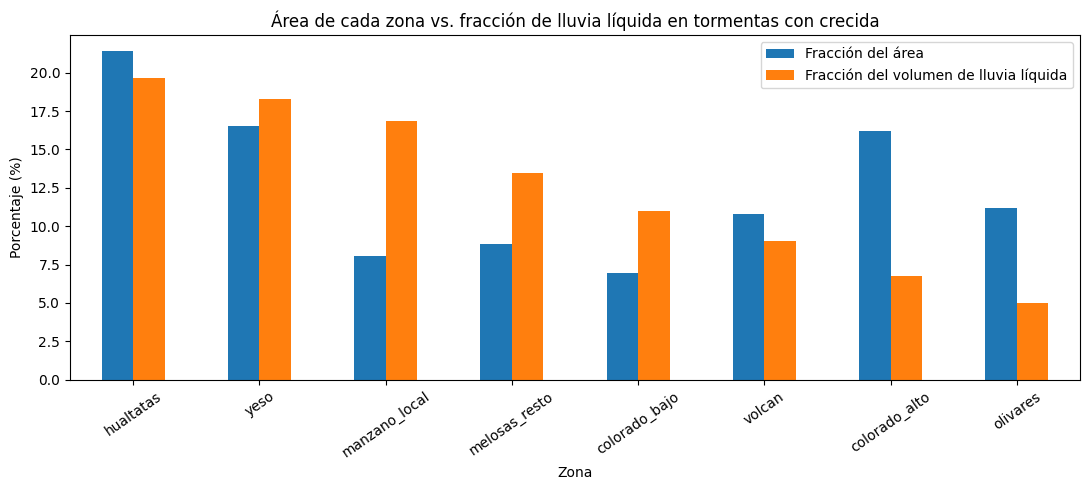

In [3]:
import matplotlib.pyplot as plt

def resumen_tipo(columna, etiqueta):
    datos = catalogo.dropna(subset=[columna, "crecida"]).copy()
    datos[columna] = datos[columna].astype(bool)
    resumen = datos.groupby(columna).agg(
        tormentas=("tormenta_id", "size"),
        crecidas=("crecida", lambda valores: valores.eq(True).sum()),
        razon_mediana=("razon_respuesta", "median"),
        eventos_documentados=("evento_documentado", "sum"),
    )
    resumen["fraccion_crecidas"] = resumen["crecidas"] / resumen["tormentas"]
    resumen.index = resumen.index.map({False: "No", True: "Sí"})
    resumen.index.name = etiqueta
    return resumen

for columna, etiqueta in [
    ("tormenta_calida", "Isoterma >= 3.000 m"),
    ("rio_atmosferico", "PW >= 20 mm e IVT >= 250 mm·m/s"),
    ("convectiva", "KI >= 30 °C"),
]:
    display(Markdown(f"### {etiqueta}"))
    display(resumen_tipo(columna, "Clasificación"))
    print(f"Tormentas sin datos suficientes para esta clasificación: {catalogo[columna].isna().sum()}")

top10_respuesta = catalogo.nlargest(10, "razon_respuesta").copy()
eventos_en_top10 = int(top10_respuesta["evento_documentado"].sum())
print(f"\nEventos documentados entre las 10 mayores razones: {eventos_en_top10}/10")
display(top10_respuesta[[
    "tormenta_id", "fecha_inicio", "fecha_fin", "razon_respuesta", "tormenta_calida",
    "rio_atmosferico", "convectiva", "evento_documentado", "eventos_documentados_ids",
]])

crecidas = catalogo.loc[catalogo["crecida"].eq(True)]
no_crecidas = catalogo.loc[catalogo["crecida"].eq(False)]
area_total_km2 = zonas["area_km2"].sum()
volumen_lluvia_crecidas = sum(
    crecidas[f"p_liq_{fila.zona}_mm"].sum() * fila.area_km2
    for fila in zonas.itertuples(index=False)
)

filas_zonas = []
for fila in zonas.itertuples(index=False):
    columna = f"p_liq_{fila.zona}_mm"
    volumen_zona = crecidas[columna].sum() * fila.area_km2
    proporcion_area = fila.area_km2 / area_total_km2
    proporcion_lluvia = volumen_zona / volumen_lluvia_crecidas
    filas_zonas.append({
        "zona": fila.zona,
        "nombre": fila.nombre,
        "area_km2": fila.area_km2,
        "area_pct": 100 * proporcion_area,
        "lluvia_liquida_media_por_crecida_mm": crecidas[columna].mean(),
        "lluvia_liquida_media_no_crecida_mm": no_crecidas[columna].mean(),
        "volumen_lluvia_crecidas_pct": 100 * proporcion_lluvia,
        "aporte_vs_area": proporcion_lluvia / proporcion_area,
    })

comparacion_zonas = pd.DataFrame(filas_zonas).sort_values(
    "volumen_lluvia_crecidas_pct", ascending=False
).reset_index(drop=True)
display(comparacion_zonas.round(2))

ax = comparacion_zonas.set_index("zona")[["area_pct", "volumen_lluvia_crecidas_pct"]].plot(
    kind="bar", figsize=(11, 5), rot=35,
    ylabel="Porcentaje (%)", title="Área de cada zona vs. fracción de lluvia líquida en tormentas con crecida",
)
ax.set_xlabel("Zona")
ax.legend(["Fracción del área", "Fracción del volumen de lluvia líquida"])
plt.tight_layout()
plt.show()


## 3. Extra: fases del ONI

Agrupamos los inviernos con el promedio de los cinco valores mensuales de ONI de mayo a septiembre: El Niño (`>= 0,5`), La Niña (`<= -0,5`) y neutro (entre ambos). Para que los años sean comparables excluimos temporadas con menos de cinco meses; en esta serie 2026 está incompleto. Contrastamos la isoterma media de los días con precipitación, el volumen proxy de lluvia líquida y la frecuencia de crecidas. Con pocas temporadas —en especial pocos El Niño— la diferencia se debe tratar como descriptiva, no concluyente.

In [4]:
meses_oni = df.loc[
    df["fecha"].dt.month.between(5, 9), ["anio_hidro", "fecha", "oni"]
].copy()
meses_oni["mes"] = meses_oni["fecha"].dt.month
variacion_oni_mensual = meses_oni.groupby(["anio_hidro", "mes"])["oni"].nunique()
assert variacion_oni_mensual.le(1).all(), "ONI cambia dentro de un mismo mes"

oni_mensual = meses_oni.drop_duplicates(["anio_hidro", "mes"])
oni_invierno = oni_mensual.groupby("anio_hidro").agg(
    oni_medio_mayo_sep=("oni", "mean"), meses_oni=("mes", "nunique")
).reset_index()

def clasificar_oni(valor):
    if valor >= 0.5:
        return "El Niño"
    if valor <= -0.5:
        return "La Niña"
    return "Neutro"

oni_invierno["fase_oni"] = oni_invierno["oni_medio_mayo_sep"].map(clasificar_oni)
anios_completos = oni_invierno.loc[oni_invierno["meses_oni"].eq(5), "anio_hidro"]
print("Temporadas ONI incompletas excluidas:")
display(oni_invierno.loc[oni_invierno["meses_oni"].lt(5)])

dias_lluvia_invierno = df.loc[
    df["fecha"].dt.month.between(4, 9) & df["p_mm"].gt(0)
]
iso0_anual = dias_lluvia_invierno.groupby("anio_hidro").agg(
    dias_con_lluvia=("fecha", "size"), iso0_media_dias_lluvia=("iso0_m", "mean")
).reset_index()

dias_invierno = df.loc[df["fecha"].dt.month.between(4, 9)].copy()
dias_invierno["lluvia_liquida_area_mm_km2"] = sum(
    dias_invierno[f"p_liq_{fila.zona}_mm"] * fila.area_km2
    for fila in zonas.itertuples(index=False)
)
lluvia_liquida_anual = dias_invierno.groupby("anio_hidro").agg(
    lluvia_liquida_mm_km2=("lluvia_liquida_area_mm_km2", "sum")
).reset_index()

catalogo_oni = catalogo.dropna(subset=["crecida"]).copy()
anio_por_fecha = df.set_index("fecha")["anio_hidro"]
catalogo_oni["anio_hidro"] = catalogo_oni["fecha_inicio"].map(anio_por_fecha)
catalogo_oni["crecida_num"] = catalogo_oni["crecida"].astype(int)
crecidas_anuales = catalogo_oni.groupby("anio_hidro").agg(
    tormentas=("tormenta_id", "size"), crecidas=("crecida_num", "sum")
).reset_index()
crecidas_anuales["fraccion_crecidas"] = crecidas_anuales["crecidas"] / crecidas_anuales["tormentas"]

resumen_anual_oni = (
    oni_invierno.merge(iso0_anual, on="anio_hidro", how="left")
    .merge(lluvia_liquida_anual, on="anio_hidro", how="left")
    .merge(crecidas_anuales, on="anio_hidro", how="left")
)
resumen_anual_oni["tormentas"] = resumen_anual_oni["tormentas"].fillna(0).astype(int)
resumen_anual_oni["crecidas"] = resumen_anual_oni["crecidas"].fillna(0).astype(int)
resumen_anual_oni["fraccion_crecidas"] = (
    resumen_anual_oni["crecidas"] / resumen_anual_oni["tormentas"].replace(0, pd.NA)
)
resumen_anual_oni = resumen_anual_oni.loc[
    resumen_anual_oni["anio_hidro"].isin(anios_completos)
].copy()
resumen_fases_oni = resumen_anual_oni.groupby("fase_oni").agg(
    inviernos=("anio_hidro", "nunique"),
    oni_medio=("oni_medio_mayo_sep", "mean"),
    iso0_media_dias_lluvia_m=("iso0_media_dias_lluvia", "mean"),
    lluvia_liquida_media_mm_km2=("lluvia_liquida_mm_km2", "mean"),
    tormentas_media=("tormentas", "mean"),
    crecidas_media=("crecidas", "mean"),
    fraccion_crecidas_media=("fraccion_crecidas", "mean"),
).sort_values("inviernos", ascending=False)
print(f"Inviernos completos comparados: {len(resumen_anual_oni)}")
display(resumen_fases_oni.round(2))


Temporadas ONI incompletas excluidas:


,anio_hidro,oni_medio_mayo_sep,meses_oni,fase_oni
26,2026,1.38,3,El Niño


Inviernos completos comparados: 26


,inviernos,oni_medio,iso0_media_dias_lluvia_m,lluvia_liquida_media_mm_km2,tormentas_media,crecidas_media,fraccion_crecidas_media
fase_oni,,,,,,,
Neutro,19,-0.01,2965.00,1481456.96,12.79,0.47,0.03
La Niña,4,-0.70,2685.95,1046662.93,12.00,0.50,0.04
El Niño,3,1.01,2927.26,1890748.00,12.67,1.33,0.10


## 4. Modelo simple por tormenta

El objetivo es `crecida` (razon de respuesta de caudal >= 3). Las tormentas con ventanas incompletas de caudal permanecen en el catalogo, pero no se entrenan como 0/1. Las predicciones usan solo los tres tipos de tormenta y la lluvia liquida de las ocho zonas. Caudal, razon de respuesta y eventos documentados se excluyen de `X`. Se deja fuera un año hidrológico completo por pliegue (`LeaveOneGroupOut`); imputación y escalado se ajustan solo con los años de entrenamiento. Comparamos el `average_precision_score` agrupado de las predicciones fuera de muestra con la regla indicada en el enunciado: ordenar por la lluvia líquida total de las ocho zonas durante la tormenta. Como referencia secundaria, también evaluamos ese total ponderado por área (`mm × km²`), que aproxima volumen sobre las zonas no solapadas.

In [5]:
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

columnas_lluvia_zonal = [f"p_liq_{zona}_mm" for zona in zonas["zona"]]
columnas_tipo = ["tormenta_calida", "rio_atmosferico", "convectiva"]
columnas_predictoras = columnas_tipo + columnas_lluvia_zonal
columnas_prohibidas = {
    "q_mediana_7d_previos_m3s", "q_max_respuesta_m3s", "razon_respuesta",
    "crecida", "evento_documentado", "eventos_documentados_ids",
}
assert not (set(columnas_predictoras) & columnas_prohibidas)

catalogo_modelo = catalogo.dropna(subset=["crecida"]).copy().reset_index(drop=True)


def matriz_X(tabla):
    """Tipos de tormenta a 0/1 (NaN si falta el sondeo) + lluvia líquida de las 8 zonas."""
    X = tabla[columnas_predictoras].copy()
    for columna in columnas_tipo:
        X[columna] = X[columna].map({True: 1.0, False: 0.0})
    return X.astype("float64")


X = matriz_X(catalogo_modelo)
y = catalogo_modelo["crecida"].astype(int)
anio_por_fecha = df.set_index("fecha")["anio_hidro"]
grupos = catalogo_modelo["fecha_inicio"].map(anio_por_fecha)

area_por_zona = zonas.set_index("zona")["area_km2"]
baseline_lluvia_total = catalogo_modelo["p_liq_total_zonas_mm"]
baseline_lluvia_area = sum(
    catalogo_modelo[f"p_liq_{zona}_mm"] * area_por_zona[zona]
    for zona in zonas["zona"]
)



def nuevo_modelo():
    """Imputación y escalado dentro del pipeline: se ajustan solo con los años de entrenamiento."""
    return Pipeline([
        ("imputador", SimpleImputer(strategy="median", add_indicator=True)),
        ("escalador", StandardScaler()),
        ("clasificador", LogisticRegression(class_weight="balanced", max_iter=2000)),
    ])


logo = LeaveOneGroupOut()
predicciones_oof = pd.Series(np.nan, index=X.index, dtype="float64")
resultados_pliegues = []
coeficientes = []

for indices_train, indices_test in logo.split(X, y, groups=grupos):
    X_train, X_test = X.iloc[indices_train], X.iloc[indices_test]
    y_train, y_test = y.iloc[indices_train], y.iloc[indices_test]
    if y_train.nunique() != 2:
        raise ValueError("Un pliegue dejó al conjunto de entrenamiento con una sola clase")

    modelo = nuevo_modelo()
    modelo.fit(X_train, y_train)
    probabilidad = modelo.predict_proba(X_test)[:, 1]
    predicciones_oof.iloc[indices_test] = probabilidad

    positivos_test = int(y_test.sum())
    ap_modelo = average_precision_score(y_test, probabilidad) if positivos_test else np.nan
    ap_baseline = (
        average_precision_score(y_test, baseline_lluvia_total.iloc[indices_test])
        if positivos_test else np.nan
    )
    ap_baseline_area = (
        average_precision_score(y_test, baseline_lluvia_area.iloc[indices_test])
        if positivos_test else np.nan
    )
    anio_test = int(grupos.iloc[indices_test[0]])
    resultados_pliegues.append({
        "anio_hidro_test": anio_test,
        "tormentas_test": len(indices_test),
        "crecidas_test": positivos_test,
        "pr_auc_modelo": ap_modelo,
        "pr_auc_baseline": ap_baseline,
        "pr_auc_baseline_area": ap_baseline_area,
    })

    nombres = modelo.named_steps["imputador"].get_feature_names_out(columnas_predictoras)
    valores_coef = modelo.named_steps["clasificador"].coef_[0]
    coeficientes.extend(
        {"anio_hidro_test": anio_test, "variable": nombre, "coeficiente": valor}
        for nombre, valor in zip(nombres, valores_coef)
    )

assert predicciones_oof.notna().all(), "Hay tormentas sin predicción fuera de muestra"
pr_auc_modelo = average_precision_score(y, predicciones_oof)
pr_auc_baseline = average_precision_score(y, baseline_lluvia_total)
pr_auc_baseline_area = average_precision_score(y, baseline_lluvia_area)
pliegues = pd.DataFrame(resultados_pliegues).sort_values("anio_hidro_test")
pliegues_con_positivos = pliegues.loc[pliegues["crecidas_test"].gt(0)]
pr_auc_macro_modelo = pliegues_con_positivos["pr_auc_modelo"].mean()
pr_auc_macro_baseline = pliegues_con_positivos["pr_auc_baseline"].mean()
pr_auc_macro_baseline_area = pliegues_con_positivos["pr_auc_baseline_area"].mean()
print(f"Tormentas etiquetadas: {len(y)} de {len(catalogo)} | sin etiqueta por caudal incompleto: {catalogo['crecida'].isna().sum()}")
print(f"Crecidas: {int(y.sum())} ({y.mean():.1%}) | anios LOGO: {grupos.nunique()}")
print(f"PR-AUC modelo (predicciones LOGO agrupadas): {pr_auc_modelo:.3f}")
print(f"PR-AUC baseline requerido (lluvia líquida total): {pr_auc_baseline:.3f}")
print(f"PR-AUC baseline secundario (ponderado por área): {pr_auc_baseline_area:.3f}")
print(f"Diferencia modelo - baseline requerido: {pr_auc_modelo - pr_auc_baseline:+.3f}")
print(f"PR-AUC macro modelo (años de prueba con crecidas): {pr_auc_macro_modelo:.3f}")
print(f"PR-AUC macro baseline requerido (mismos años): {pr_auc_macro_baseline:.3f}")
print(f"PR-AUC macro baseline por área (mismos años): {pr_auc_macro_baseline_area:.3f}")
print(f"Años de prueba con crecidas: {len(pliegues_con_positivos)}")
print("  (macro = media de AP por año: con 1 sola crecida en el año, AP = 1/posición de esa crecida "
      "(1, 0.5, 0.33...), así que es inestable; el veredicto usa la PR-AUC agrupada)")
# el veredicto modelo vs baseline se decide con el IC del bootstrap (celda siguiente), no con la diferencia puntual

print("PR-AUC por año de prueba (los años sin crecidas no tienen AP definido):")
display(pliegues.round(3))

coeficientes_df = pd.DataFrame(coeficientes)
resumen_coeficientes = coeficientes_df.groupby("variable").agg(
    coeficiente_mediano=("coeficiente", "median"),
    magnitud_media_absoluta=("coeficiente", lambda valores: valores.abs().mean()),
    pliegues_con_variable=("coeficiente", "count"),
).sort_values("magnitud_media_absoluta", ascending=False)
print("Coeficientes estandarizados: dirección y magnitud descriptivas, no causales.")
display(resumen_coeficientes.round(3))

Tormentas etiquetadas: 334 de 346 | sin etiqueta por caudal incompleto: 12
Crecidas: 16 (4.8%) | anios LOGO: 27
PR-AUC modelo (predicciones LOGO agrupadas): 0.818
PR-AUC baseline requerido (lluvia líquida total): 0.790
PR-AUC baseline secundario (ponderado por área): 0.781
Diferencia modelo - baseline requerido: +0.028
PR-AUC macro modelo (años de prueba con crecidas): 0.944
PR-AUC macro baseline requerido (mismos años): 0.903
PR-AUC macro baseline por área (mismos años): 0.861
Años de prueba con crecidas: 12
  (macro = media de AP por año: con 1 sola crecida en el año, AP = 1/posición de esa crecida (1, 0.5, 0.33...), así que es inestable; el veredicto usa la PR-AUC agrupada)
PR-AUC por año de prueba (los años sin crecidas no tienen AP definido):


,anio_hidro_test,tormentas_test,crecidas_test,pr_auc_modelo,pr_auc_baseline,pr_auc_baseline_area
0,2000,13,2,1.000,1.000,1.000
1,2001,16,1,1.000,1.000,0.500
2,2002,11,1,0.333,0.333,0.333
3,2003,8,0,NaN,NaN,NaN
4,2004,11,0,NaN,NaN,NaN
5,2005,22,1,1.000,1.000,1.000
6,2006,16,1,1.000,1.000,1.000
7,2007,16,0,NaN,NaN,NaN
8,2008,15,3,1.000,1.000,1.000
9,2009,15,1,1.000,0.500,0.500


Coeficientes estandarizados: dirección y magnitud descriptivas, no causales.


,coeficiente_mediano,magnitud_media_absoluta,pliegues_con_variable
variable,,,
rio_atmosferico,1.132,1.114,27
p_liq_manzano_local_mm,1.034,1.031,27
p_liq_yeso_mm,0.813,0.801,27
convectiva,0.695,0.723,27
p_liq_olivares_mm,0.515,0.522,27
p_liq_colorado_bajo_mm,0.488,0.511,27
p_liq_melosas_resto_mm,0.385,0.384,27
p_liq_volcan_mm,0.225,0.225,27
tormenta_calida,-0.160,0.189,27


In [6]:
# Incertidumbre: ¿la ventaja del modelo sobre el baseline es más grande que el ruido?
# Bootstrap por año hidrológico (se remuestrean años completos, igual que en LOGO), 2000 repeticiones
rng = np.random.default_rng(0)
anios = grupos.unique()
diferencias = []
for _ in range(2000):
    muestra = np.concatenate([np.flatnonzero(grupos.eq(a)) for a in rng.choice(anios, len(anios))])
    if y.iloc[muestra].sum() == 0:
        continue
    diferencias.append(average_precision_score(y.iloc[muestra], predicciones_oof.iloc[muestra])
                       - average_precision_score(y.iloc[muestra], baseline_lluvia_total.iloc[muestra]))
diferencias = np.array(diferencias)
ic_bajo, ic_alto = np.percentile(diferencias, [2.5, 97.5])
print(f"Diferencia PR-AUC modelo - baseline: {pr_auc_modelo - pr_auc_baseline:+.3f} | "
      f"IC 95 % [{ic_bajo:+.3f}, {ic_alto:+.3f}] | el modelo gana en {np.mean(diferencias > 0):.0%} de las réplicas")
if ic_bajo > 0:
    print("Veredicto: el modelo supera al baseline (el IC 95 % no incluye el 0).")
elif ic_alto < 0:
    print("Veredicto: el baseline supera al modelo (el IC 95 % no incluye el 0).")
else:
    print("Veredicto: el modelo no se distingue del baseline (el IC 95 % incluye el 0).")

# Regla física sin entrenamiento: primero los ríos atmosféricos, después ordenar por lluvia líquida total.
# Es post-hoc: se armó después de ver que las crecidas son RA, así que su PR-AUC es optimista.
es_ra = catalogo_modelo["rio_atmosferico"].eq(True)
crecidas_ra = int(y[es_ra].sum())
regla_ra = es_ra.astype(float) * (baseline_lluvia_total.max() + 1) + baseline_lluvia_total
pr_auc_regla_ra = average_precision_score(y, regla_ra)
print(f"Crecidas en ríos atmosféricos: {crecidas_ra}/{int(y.sum())} "
      f"(tormentas RA: {int(es_ra.sum())}, sin dato de sondeo: {int(catalogo_modelo['rio_atmosferico'].isna().sum())})")
print(f"PR-AUC regla 'río atmosférico + lluvia líquida' (post-hoc): {pr_auc_regla_ra:.3f} (modelo {pr_auc_modelo:.3f})")


Diferencia PR-AUC modelo - baseline: +0.028 | IC 95 % [-0.072, +0.118] | el modelo gana en 76% de las réplicas
Veredicto: el modelo no se distingue del baseline (el IC 95 % incluye el 0).
Crecidas en ríos atmosféricos: 16/16 (tormentas RA: 89, sin dato de sondeo: 19)
PR-AUC regla 'río atmosférico + lluvia líquida' (post-hoc): 0.794 (modelo 0.818)


## 4b. Robustez del resultado

Con 16 crecidas, una diferencia de +0.028 puede depender de decisiones de diseño. Con el mismo pipeline y el mismo LOGO probamos: (1) la **etiqueta**: umbrales vecinos al del enunciado, referencia de caudal medida antes de una cadena de tormentas y quitar una crecida a la vez; (2) las **variables**: quitar cada tipo de tormenta de `X` y medir la colinealidad; (3) las **tormentas sin etiqueta**: si podrían esconder crecidas.

In [7]:
# Robustez de la etiqueta: ¿la ventaja del modelo sobrevive a definiciones razonables de "crecida"?
def pr_auc_logo(X, y, grupos):
    """PR-AUC de las predicciones LOGO agrupadas, con el mismo pipeline de la sección 4."""
    oof = pd.Series(np.nan, index=X.index)
    for indices_train, indices_test in LeaveOneGroupOut().split(X, y, groups=grupos):
        oof.iloc[indices_test] = (nuevo_modelo().fit(X.iloc[indices_train], y.iloc[indices_train])
                                  .predict_proba(X.iloc[indices_test])[:, 1])
    return average_precision_score(y, oof)


# 1) umbral de crecida: el enunciado fija razón >= 3; ¿qué pasa con umbrales vecinos?
razon = catalogo_modelo["razon_respuesta"]
filas_umbral = []
for umbral in [2, 2.5, 3, 4, 5]:
    y_umbral = razon.ge(umbral).astype(int)
    filas_umbral.append({
        "umbral_razon": umbral, "crecidas": int(y_umbral.sum()),
        "pr_auc_modelo": pr_auc_logo(X, y_umbral, grupos),
        "pr_auc_baseline": average_precision_score(y_umbral, baseline_lluvia_total),
    })
sensibilidad_umbral = pd.DataFrame(filas_umbral)
sensibilidad_umbral["diferencia"] = sensibilidad_umbral["pr_auc_modelo"] - sensibilidad_umbral["pr_auc_baseline"]
display(Markdown("### Sensibilidad al umbral de crecida"))
display(sensibilidad_umbral.round(3))

# 2) tormentas encadenadas: si una tormenta empieza <= 7 días después de que terminó la anterior, su referencia
# de 7 días incluye días de esa tormenta: el caudal base viene elevado, el denominador se infla y la razón baja.
# Alternativa: medir la referencia antes del inicio de la cadena (misma exigencia de 7 días con caudal).
separacion = (catalogo["fecha_inicio"] - catalogo["fecha_fin"].shift()).dt.days
encadenada = separacion.le(7)
inicio_cadena = catalogo.groupby((~encadenada).cumsum())["fecha_inicio"].transform("min")
q_dia = df.set_index("fecha")["q_m3s"]


def mediana_7d_previa(inicio):
    referencia = q_dia[inicio - pd.Timedelta(days=7): inicio - pd.Timedelta(days=1)].dropna()
    return referencia.median() if len(referencia) == 7 else np.nan


comparables = (catalogo.assign(razon_cadena=catalogo["q_max_respuesta_m3s"] / inicio_cadena.map(mediana_7d_previa))
               .dropna(subset=["razon_respuesta", "razon_cadena"]).reset_index(drop=True))
crecida_original = comparables["razon_respuesta"].ge(3)
crecida_cadena = comparables["razon_cadena"].ge(3)
y_cadena = crecida_cadena.astype(int)
display(Markdown("### Tormentas encadenadas"))
print(f"Tormentas que empiezan <= 7 días después de otra: {int(encadenada.sum())} de {len(catalogo)} "
      f"(crecidas: {int((encadenada & catalogo['crecida'].eq(True)).sum())} de {int(catalogo['crecida'].eq(True).sum())})")
print(f"Referencia al inicio de la cadena ({len(comparables)} tormentas comparables): crecidas "
      f"{int(crecida_original.sum())} -> {int(crecida_cadena.sum())} (ganan {int((crecida_cadena & ~crecida_original).sum())}, "
      f"pierden {int((crecida_original & ~crecida_cadena).sum())}) | todas río atmosférico: "
      f"{bool(comparables.loc[crecida_cadena, 'rio_atmosferico'].eq(True).all())}")
print(f"PR-AUC con esa etiqueta: modelo "
      f"{pr_auc_logo(matriz_X(comparables), y_cadena, comparables['fecha_inicio'].map(anio_por_fecha)):.3f} "
      f"vs baseline {average_precision_score(y_cadena, comparables['p_liq_total_zonas_mm']):.3f}")
display(comparables.loc[crecida_original != crecida_cadena, [
    "fecha_inicio", "fecha_fin", "razon_respuesta", "razon_cadena", "rio_atmosferico", "evento_documentado",
]].round(2))

# 3) quitar una crecida a la vez: ¿la diferencia depende de una sola tormenta?
filas_sin_una = []
for indice in y.index[y.eq(1)]:
    resto = y.index != indice
    filas_sin_una.append({
        "fecha_inicio": catalogo_modelo.at[indice, "fecha_inicio"].date(),
        "razon_respuesta": razon[indice],
        "diferencia_sin_ella": pr_auc_logo(X[resto], y[resto], grupos[resto])
                               - average_precision_score(y[resto], baseline_lluvia_total[resto]),
    })
sin_una_crecida = pd.DataFrame(filas_sin_una)
display(Markdown("### Quitar una crecida a la vez"))
print(f"Diferencia modelo - baseline al quitar una crecida: de {sin_una_crecida['diferencia_sin_ella'].min():+.3f} "
      f"a {sin_una_crecida['diferencia_sin_ella'].max():+.3f}; "
      f"el baseline gana en {int(sin_una_crecida['diferencia_sin_ella'].lt(0).sum())} de {len(sin_una_crecida)} casos")
display(sin_una_crecida.round(3))


### Sensibilidad al umbral de crecida

,umbral_razon,crecidas,pr_auc_modelo,pr_auc_baseline,diferencia
0,2.0,27,0.694,0.720,-0.025
1,2.5,20,0.735,0.725,0.010
2,3.0,16,0.818,0.790,0.028
3,4.0,13,0.623,0.651,-0.028
4,5.0,8,0.609,0.691,-0.081


### Tormentas encadenadas

Tormentas que empiezan <= 7 días después de otra: 153 de 346 (crecidas: 9 de 16)
Referencia al inicio de la cadena (334 tormentas comparables): crecidas 16 -> 20 (ganan 4, pierden 0) | todas río atmosférico: True
PR-AUC con esa etiqueta: modelo 0.712 vs baseline 0.720


,fecha_inicio,fecha_fin,razon_respuesta,razon_cadena,rio_atmosferico,evento_documentado
70,2005-06-17,2005-06-18,2.74,3.59,True,False
72,2005-06-26,2005-06-28,2.71,5.51,True,False
73,2005-07-01,2005-07-02,1.07,3.13,True,False
116,2008-05-26,2008-05-27,1.12,3.05,True,False


### Quitar una crecida a la vez

Diferencia modelo - baseline al quitar una crecida: de -0.015 a +0.101; el baseline gana en 2 de 16 casos


,fecha_inicio,razon_respuesta,diferencia_sin_ella
0,2000-06-12,5.757,0.039
1,2000-06-26,4.743,-0.002
2,2001-07-16,4.056,0.009
3,2002-08-22,4.054,0.101
4,2005-08-26,3.674,0.039
5,2006-07-06,6.955,0.030
6,2008-05-17,7.943,0.028
7,2008-06-03,3.764,0.026
8,2008-08-14,4.172,-0.015
9,2009-09-04,5.336,0.001


In [8]:
# Robustez de las variables: ¿de qué tipo de tormenta viene la ventaja? ¿se pueden leer los coeficientes?
variantes = {"completo": columnas_predictoras, "solo lluvia zonal": columnas_lluvia_zonal}
variantes.update({f"sin {tipo}": [c for c in columnas_predictoras if c != tipo] for tipo in columnas_tipo})
ablacion = pd.Series({nombre: pr_auc_logo(X[cols], y, grupos) for nombre, cols in variantes.items()},
                     name="pr_auc_modelo")
display(Markdown(f"### Ablación por tipo de tormenta (baseline {pr_auc_baseline:.3f})"))
display(ablacion.round(3).to_frame())

# los tipos comparten señal de humedad e inestabilidad
tipos_bool = catalogo_modelo[columnas_tipo].dropna().astype(bool)
display(Markdown("### Colinealidad"))
display(pd.crosstab(tipos_bool["rio_atmosferico"], tipos_bool["convectiva"]))
display(tipos_bool.astype(float).corr().round(2))

# la lluvia de una tormenta cae en casi toda la cuenca a la vez: las 8 zonas son casi la misma variable
lluvia_zonal = catalogo_modelo[columnas_lluvia_zonal]
vif = pd.Series({
    columna: 1 / (1 - LinearRegression().fit(lluvia_zonal.drop(columns=columna), lluvia_zonal[columna])
                  .score(lluvia_zonal.drop(columns=columna), lluvia_zonal[columna]))
    for columna in columnas_lluvia_zonal
})
pares = lluvia_zonal.corr().where(~np.eye(len(columnas_lluvia_zonal), dtype=bool)).stack()
print(f"Lluvia zonal: correlación entre zonas mediana {pares.median():.2f} (mín {pares.min():.2f}); "
      f"VIF de {vif.min():.0f} a {vif.max():.0f} (sobre 10 ya es colinealidad fuerte)")


### Ablación por tipo de tormenta (baseline 0.790)

,pr_auc_modelo
completo,0.818
solo lluvia zonal,0.787
sin tormenta_calida,0.825
sin rio_atmosferico,0.799
sin convectiva,0.785


### Colinealidad

convectiva,False,True
rio_atmosferico,,
False,208,18
True,52,37


,tormenta_calida,rio_atmosferico,convectiva
tormenta_calida,1.00,0.24,0.14
rio_atmosferico,0.24,1.00,0.40
convectiva,0.14,0.40,1.00


Lluvia zonal: correlación entre zonas mediana 0.96 (mín 0.78); VIF de 208 a 1498 (sobre 10 ya es colinealidad fuerte)


In [9]:
# Las tormentas sin etiqueta (caudal incompleto): ¿esconden crecidas? (sesgo de selección)
sin_etiqueta = catalogo.loc[catalogo["crecida"].isna(), [
    "fecha_inicio", "fecha_fin", "n_q_validos_7d_previos", "n_q_validos_respuesta",
    "dias_respuesta_esperados", "p_liq_total_zonas_mm", "rio_atmosferico", "evento_documentado",
]].copy()
# razón parcial: la misma razón con los días que sí tienen caudal (aproximación, no etiqueta)
sin_etiqueta["razon_parcial"] = [
    q_dia[fila.fecha_inicio: fila.fecha_fin + pd.Timedelta(days=2)].max()
    / q_dia[fila.fecha_inicio - pd.Timedelta(days=7): fila.fecha_inicio - pd.Timedelta(days=1)].median()
    for fila in sin_etiqueta.itertuples()
]
display(sin_etiqueta.round(2))
print(f"Sin etiqueta: {len(sin_etiqueta)} de {len(catalogo)} | ríos atmosféricos: "
      f"{int(sin_etiqueta['rio_atmosferico'].eq(True).sum())} (sin sondeo: {int(sin_etiqueta['rio_atmosferico'].isna().sum())}) | "
      f"eventos documentados: {int(sin_etiqueta['evento_documentado'].sum())} | "
      f"razón parcial máxima: {sin_etiqueta['razon_parcial'].max():.2f} | última fecha de la serie: {df['fecha'].max().date()}")
y_con_ceros = catalogo["crecida"].eq(True).astype(int)
print(f"Tratándolas como 'sin crecida': modelo "
      f"{pr_auc_logo(matriz_X(catalogo), y_con_ceros, catalogo['fecha_inicio'].map(anio_por_fecha)):.3f} "
      f"vs baseline {average_precision_score(y_con_ceros, catalogo['p_liq_total_zonas_mm']):.3f}")


,fecha_inicio,fecha_fin,n_q_validos_7d_previos,n_q_validos_respuesta,dias_respuesta_esperados,p_liq_total_zonas_mm,rio_atmosferico,evento_documentado,razon_parcial
29,2002-05-13,2002-05-15,6,5,5,304.12,False,False,1.20
41,2002-09-14,2002-09-14,7,2,3,36.45,<NA>,False,1.01
42,2002-09-16,2002-09-16,6,3,3,36.06,False,False,1.02
138,2009-07-21,2009-07-21,6,3,3,24.32,False,False,1.00
194,2014-04-09,2014-04-09,5,3,3,64.45,False,False,0.92
238,2017-06-07,2017-06-07,6,3,3,64.79,False,False,1.25
294,2022-05-28,2022-05-28,6,3,3,23.85,False,False,0.95
295,2022-06-03,2022-06-04,6,4,4,99.63,False,False,1.12
317,2024-04-29,2024-04-29,7,2,3,30.37,False,False,0.95
318,2024-05-07,2024-05-07,6,3,3,66.75,False,False,1.10


Sin etiqueta: 12 de 346 | ríos atmosféricos: 0 (sin sondeo: 2) | eventos documentados: 0 | razón parcial máxima: 1.25 | última fecha de la serie: 2026-07-31
Tratándolas como 'sin crecida': modelo 0.817 vs baseline 0.790


## 5. Conclusiones e interpretación

La isoterma 0 °C alta puede hacer que una mayor parte de la precipitación llegue como lluvia y no como nieve. En este catálogo, la clasificación cálida por sí sola distingue la respuesta con un contraste más moderado que las categorías de río atmosférico y convectiva. Son asociaciones observacionales: no prueban causalidad ni aíslan el efecto de embalses o captaciones.

**El hallazgo más fuerte es el transporte de vapor:** las 16 crecidas ocurrieron en tormentas clasificadas como río atmosférico (`pw_mm >= 20` e `ivt_mms >= 250`), y ninguna fuera de ellas (16/89 contra 0/226). Una regla sin entrenamiento que pone primero los ríos atmosféricos y después ordena por lluvia líquida total alcanza PR-AUC 0.794, casi lo mismo que el modelo (es una regla post-hoc: se armó después de ver que las crecidas eran ríos atmosféricos). Físicamente, el río atmosférico aporta mucha agua y suele venir con isoterma alta, así que llueve, en vez de nevar, sobre una parte grande de la cuenca.

Ojo con cómo se lee: el río atmosférico es casi una **condición necesaria** (ninguna crecida fuera de él), pero no suficiente (solo 16 de 89 terminan en crecida). Ese hallazgo es robusto: si la referencia de caudal se mide antes de una cadena de tormentas, las crecidas pasan a 20 y todas siguen siendo ríos atmosféricos. Pero no es de ahí de donde sale la ventaja del modelo: sin `rio_atmosferico` el modelo da 0.799 y solo con la lluvia zonal 0.787, ambos iguales al baseline (0.790) dentro del ruido, porque un río atmosférico es justamente lo que produce mucha lluvia líquida y esa información ya está en el total. Tampoco se pueden leer los coeficientes uno por uno: 37 de los 89 ríos atmosféricos también son convectivos (correlación 0.40), y las 8 lluvias zonales son casi la misma variable (correlación mediana 0.96, VIF de 208 a 1498). Que `p_liq_manzano_local_mm` tenga coeficiente 1.03 no significa que esa zona pese más: el modelo reparte una misma señal entre variables casi iguales.

La ponderación por área respeta que las ocho zonas son particiones disjuntas. Aun así, los caudales observados en Olivares, Colorado alto y Volcán están afectados por captaciones hidroeléctricas, y El Yeso regula la zona `yeso`, según la guía del kit. La muestra de crecidas es pequeña; los episodios documentados sirven para validar contexto, no como predictores.

El modelo usa la lluvia de toda la tormenta, así que su evaluación es retrospectiva y no representa una alerta operativa antes de terminar el evento; los tipos de tormenta también se calculan con el máximo de todos sus días, así que solo se conocen al final. La comparación principal sigue la regla solicitada de ordenar por lluvia líquida total; el volumen ponderado por área queda como referencia adicional. El modelo (0.818) queda sobre esa regla (0.790) por +0.028, pero el bootstrap por año da un IC 95 % de [−0.072, +0.118]: con solo 16 crecidas, **la diferencia no se distingue del ruido**. La sección 4b lo confirma por tres lados: con umbrales de 2, 4 o 5 el modelo pierde contra el baseline; quitando una sola crecida la diferencia va de −0.015 a +0.101; y como 9 de las 16 crecidas empiezan a 7 días o menos de otra tormenta (su caudal de referencia viene elevado), al medir la referencia antes de la cadena las crecidas pasan de 16 a 20 y el modelo queda en 0.712 contra 0.720 del baseline. La conclusión honesta es que el modelo rinde parecido a la regla física, no que la supera. Se informan PR-AUC agrupada y promedio por años con crecidas; los años sin positivos no tienen AP definido. El promedio por años (0.944) es inestable: en un año con una sola crecida el AP solo puede valer 1, 0.5, 0.33…, según el lugar en que quede esa crecida; por eso el veredicto usa la PR-AUC agrupada. Las fases ONI deben interpretarse con cautela por el bajo número de inviernos El Niño y por excluir 2026 incompleto. Las 12 tormentas sin etiqueta (caudal incompleto) probablemente no esconden crecidas: ninguna es río atmosférico (2 sin sondeo) ni evento documentado, su razón parcial con los días disponibles no pasa de 1.25 y tratarlas como 'sin crecida' deja el resultado igual (0.817 vs 0.790); la del 2026-07-31 es la última fecha de la serie, sin días de respuesta. Además, el objetivo es una crecida de **caudal**, no de turbiedad: una tormenta que enturbia el río sin triplicar el caudal no cuenta aquí como crecida. Los 18 episodios documentados de este nivel (2000–2026) son coherentes con los 16 del Nivel 1, que se limita a 2000–2018.

In [10]:
eventos_asociados = {
    int(evento_id)
    for ids in catalogo.loc[catalogo["evento_documentado"], "eventos_documentados_ids"]
    if ids
    for evento_id in ids.split(", ")
}
mejor_aporte = comparacion_zonas.sort_values("aporte_vs_area", ascending=False).iloc[0]
menor_aporte = comparacion_zonas.sort_values("aporte_vs_area").iloc[0]
print(f"Catálogo: {len(catalogo)} tormentas; {catalogo['crecida'].notna().sum()} con etiqueta de caudal completa; "
      f"{catalogo['crecida'].isna().sum()} sin etiqueta por faltantes.")
print(f"Episodios documentados asociados: {len(eventos_asociados)} de {len(eventos_documentados)}; "
      f"eventos documentados en el top 10: {eventos_en_top10}/10.")
for columna, etiqueta in [("tormenta_calida", "Cálidas"), ("rio_atmosferico", "Ríos atmosféricos"), ("convectiva", "Convectivas")]:
    datos_tipo = catalogo.dropna(subset=[columna, "crecida"])
    clasificacion = datos_tipo[columna].astype(bool)
    for valor, nombre in [(True, "Sí"), (False, "No")]:
        grupo = datos_tipo.loc[clasificacion.eq(valor), "crecida"]
        positivas = int(grupo.eq(True).sum())
        total = len(grupo)
        tasa = positivas / total if total else float("nan")
        print(f"{etiqueta}={nombre}: {positivas}/{total} crecidas ({tasa:.1%}).")
    print(f"Sin clasificación para {etiqueta.lower()}: {catalogo[columna].isna().sum()} tormentas.")
print(f"Mayor aporte de lluvia respecto al área: {mejor_aporte['zona']} ({mejor_aporte['aporte_vs_area']:.2f}x); "
      f"menor: {menor_aporte['zona']} ({menor_aporte['aporte_vs_area']:.2f}x).")
print(f"PR-AUC agrupada: modelo {pr_auc_modelo:.3f}, baseline {pr_auc_baseline:.3f}; "
      f"macro en años con positivos: modelo {pr_auc_macro_modelo:.3f}, "
      f"lluvia total {pr_auc_macro_baseline:.3f}, ponderado por área {pr_auc_macro_baseline_area:.3f}.")
print(f"Inviernos completos por fase ONI: {resumen_fases_oni['inviernos'].to_dict()}.")

Catálogo: 346 tormentas; 334 con etiqueta de caudal completa; 12 sin etiqueta por faltantes.
Episodios documentados asociados: 18 de 18; eventos documentados en el top 10: 7/10.
Cálidas=Sí: 12/204 crecidas (5.9%).
Cálidas=No: 4/130 crecidas (3.1%).
Sin clasificación para cálidas: 0 tormentas.
Ríos atmosféricos=Sí: 16/89 crecidas (18.0%).
Ríos atmosféricos=No: 0/226 crecidas (0.0%).
Sin clasificación para ríos atmosféricos: 21 tormentas.
Convectivas=Sí: 14/55 crecidas (25.5%).
Convectivas=No: 2/267 crecidas (0.7%).
Sin clasificación para convectivas: 13 tormentas.
Mayor aporte de lluvia respecto al área: manzano_local (2.10x); menor: colorado_alto (0.42x).
PR-AUC agrupada: modelo 0.818, baseline 0.790; macro en años con positivos: modelo 0.944, lluvia total 0.903, ponderado por área 0.861.
Inviernos completos por fase ONI: {'Neutro': 19, 'La Niña': 4, 'El Niño': 3}.
